In [1]:

import pandas as pd
from pathlib import Path
from IPython.display import display

# ============================================================
# RQ4 - STEP 7.1A
# INSPECT ORIGINAL DATA AND BA COMPARISON COHORT
# ============================================================

DATA_DIR = Path(r"E:\Analytic Plan BI\LinkedIn Dataset")
OUTPUT_DIR = DATA_DIR / "Assignment_2_Analysis"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

original_path = DATA_DIR / "linkedin_job_postings.csv"
ba_path = OUTPUT_DIR / "US_BA_GEOGRAPHY.csv"
ba_skills_path = OUTPUT_DIR / "US_BA_SKILLS_STANDARDISED.csv"

# 1. Inspect original dataset structure
original_sample = pd.read_csv(
    original_path,
    nrows=10,
    low_memory=False
)

print("=" * 65)
print("RQ4 - ORIGINAL DATASET STRUCTURE")
print("=" * 65)

print("\nOriginal dataset columns:")
print(original_sample.columns.tolist())

print("\nOriginal dataset sample:")
display(original_sample.head(5))

# 2. Load established BA cohort
ba_jobs = pd.read_csv(
    ba_path,
    low_memory=False
)

ba_skills = pd.read_csv(
    ba_skills_path,
    low_memory=False
)

print("\n" + "=" * 65)
print("RQ4 - EXISTING BA COHORT")
print("=" * 65)

print("BA advertisements:", ba_jobs["job_link"].nunique())
print("BA advertisements with skills:",
      ba_skills["job_link"].nunique())

print("\nBA cohort columns:")
print(ba_jobs.columns.tolist())

print("\nBA job title examples:")
if "job_title" in ba_jobs.columns:
    display(ba_jobs["job_title"].value_counts().head(20))
elif "title" in ba_jobs.columns:
    display(ba_jobs["title"].value_counts().head(20))
else:
    print("No obvious title column found.")

# 3. Check identifiers
print("\n" + "=" * 65)
print("RQ4 - IDENTIFIER VALIDATION")
print("=" * 65)

print("Missing BA job links:",
      ba_jobs["job_link"].isna().sum())

print("Duplicate BA job links:",
      ba_jobs["job_link"].duplicated().sum())

print("Missing BA skill job links:",
      ba_skills["job_link"].isna().sum())

print("\nStep 7.1A inspection completed.")


RQ4 - ORIGINAL DATASET STRUCTURE

Original dataset columns:
['job_link', 'last_processed_time', 'got_summary', 'got_ner', 'is_being_worked', 'job_title', 'company', 'job_location', 'first_seen', 'search_city', 'search_country', 'search_position', 'job_level', 'job_type']

Original dataset sample:


,job_link,last_processed_time,got_summary,got_ner,is_being_worked,job_title,company,job_location,first_seen,search_city,search_country,search_position,job_level,job_type
0,https://www.linkedin.com/jobs/view/account-exe...,2024-01-21 07:12:29.00256+00,t,t,f,Account Executive - Dispensing (NorCal/Norther...,BD,"San Diego, CA",2024-01-15,Coronado,United States,Color Maker,Mid senior,Onsite
1,https://www.linkedin.com/jobs/view/registered-...,2024-01-21 07:39:58.88137+00,t,t,f,Registered Nurse - RN Care Manager,Trinity Health MI,"Norton Shores, MI",2024-01-14,Grand Haven,United States,Director Nursing Service,Mid senior,Onsite
2,https://www.linkedin.com/jobs/view/restaurant-...,2024-01-21 07:40:00.251126+00,t,t,f,RESTAURANT SUPERVISOR - THE FORKLIFT,Wasatch Adaptive Sports,"Sandy, UT",2024-01-14,Tooele,United States,Stand-In,Mid senior,Onsite
3,https://www.linkedin.com/jobs/view/independent...,2024-01-21 07:40:00.308133+00,t,t,f,Independent Real Estate Agent,Howard Hanna | Rand Realty,"Englewood Cliffs, NJ",2024-01-16,Pinehurst,United States,Real-Estate Clerk,Mid senior,Onsite
4,https://www.linkedin.com/jobs/view/group-unit-...,2024-01-19 09:45:09.215838+00,f,f,f,Group/Unit Supervisor (Systems Support Manager...,"IRS, Office of Chief Counsel","Chamblee, GA",2024-01-17,Gadsden,United States,Supervisor Travel-Information Center,Mid senior,Onsite



RQ4 - EXISTING BA COHORT
BA advertisements: 3722
BA advertisements with skills: 3606

BA cohort columns:
['job_link', 'job_title', 'company', 'job_location', 'first_seen', 'search_city', 'search_country', 'search_position', 'job_level', 'job_type', 'state_clean', 'location_country_issue']

BA job title examples:


job_title
Business Analyst                                         768
JDE Business Analyst (Supply Chain)                      163
JD Edwards Business Analyst                              150
Senior Business Analyst                                  137
IT Business Analyst                                       53
Business Analyst II                                       49
Technical Business Analyst                                42
Business Analyst III                                      36
Business Analyst I                                        28
Sr. Business Analyst                                      26
Senior Financial Business Analyst - Tax Technology        22
Salesforce Business Analyst                               21
Guidewire Business Analyst - Senior Associate             18
Sr Business Analyst                                       16
ERP Fin Business Analyst                                  15
ERP Business Analyst                                      15
Business Analy


RQ4 - IDENTIFIER VALIDATION
Missing BA job links: 0
Duplicate BA job links: 0
Missing BA skill job links: 0

Step 7.1A inspection completed.


In [2]:

import pandas as pd
from pathlib import Path
from IPython.display import display

# ============================================================
# RQ4 - STEP 7.1B
# CONSTRUCT US NON-BA COMPARISON GROUP
# ============================================================

DATA_DIR = Path(r"E:\Analytic Plan BI\LinkedIn Dataset")
OUTPUT_DIR = DATA_DIR / "Assignment_2_Analysis"

# ------------------------------------------------------------
# 1. Load established BA cohort
# ------------------------------------------------------------

ba_jobs = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv",
    dtype={"job_link": "string"},
    low_memory=False
)

ba_links = set(
    ba_jobs["job_link"].dropna()
)

# ------------------------------------------------------------
# 2. Load only required original columns
# ------------------------------------------------------------

required_columns = [
    "job_link",
    "job_title",
    "company",
    "job_location",
    "search_country",
    "job_level",
    "job_type"
]

original_jobs = pd.read_csv(
    DATA_DIR / "linkedin_job_postings.csv",
    usecols=required_columns,
    dtype={"job_link": "string"},
    low_memory=False
)

print("=" * 65)
print("RQ4 - ORIGINAL DATASET")
print("=" * 65)

print("Original records:", len(original_jobs))

# ------------------------------------------------------------
# 3. Retain US advertisements
# ------------------------------------------------------------

us_jobs = original_jobs[
    original_jobs["search_country"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.casefold()
    .eq("united states")
].copy()

print("\nUS records before deduplication:", len(us_jobs))

# Remove missing identifiers and duplicates
us_jobs = us_jobs.dropna(subset=["job_link"])
us_jobs = us_jobs.drop_duplicates(subset=["job_link"])

print("Unique US advertisements:", len(us_jobs))

# ------------------------------------------------------------
# 4. Exclude established BA cohort
# ------------------------------------------------------------

us_non_ba = us_jobs[
    ~us_jobs["job_link"].isin(ba_links)
].copy()

print("\nAfter excluding existing BA cohort:", len(us_non_ba))

# ------------------------------------------------------------
# 5. Exclude additional BA-title advertisements
# ------------------------------------------------------------

# Match Business Analyst and spacing/hyphen variants
ba_title_pattern = r"\bbusiness[\s\-]+analyst\b"

additional_ba_mask = (
    us_non_ba["job_title"]
    .fillna("")
    .astype(str)
    .str.contains(
        ba_title_pattern,
        case=False,
        regex=True
    )
)

additional_ba_count = int(additional_ba_mask.sum())

us_non_ba = us_non_ba[
    ~additional_ba_mask
].copy()

# ------------------------------------------------------------
# 6. Validate comparison group
# ------------------------------------------------------------

overlap_count = us_non_ba[
    "job_link"
].isin(ba_links).sum()

remaining_ba_titles = (
    us_non_ba["job_title"]
    .fillna("")
    .astype(str)
    .str.contains(
        ba_title_pattern,
        case=False,
        regex=True
    )
    .sum()
)

print("\n" + "=" * 65)
print("RQ4 - NON-BA COMPARISON COHORT")
print("=" * 65)

print("Established BA advertisements:", len(ba_jobs))
print("Additional BA-title advertisements excluded:",
      additional_ba_count)

print("Final US non-BA advertisements:", len(us_non_ba))
print("Unique non-BA job links:",
      us_non_ba["job_link"].nunique())

print("\nVALIDATION")
print("Overlap with established BA cohort:", overlap_count)
print("Remaining Business Analyst titles:", remaining_ba_titles)
print("Duplicate non-BA job links:",
      us_non_ba["job_link"].duplicated().sum())

print("\nTOP 20 NON-BA JOB TITLES:")
display(
    us_non_ba["job_title"]
    .value_counts()
    .head(20)
)

# ------------------------------------------------------------
# 7. Save comparison cohort
# ------------------------------------------------------------

us_non_ba.to_csv(
    OUTPUT_DIR / "RQ4_US_NON_BA_JOBS.csv",
    index=False
)

print("\nNon-BA comparison cohort saved successfully.")


RQ4 - ORIGINAL DATASET
Original records: 1348454

US records before deduplication: 1149342
Unique US advertisements: 1149342

After excluding existing BA cohort: 1145620

RQ4 - NON-BA COMPARISON COHORT
Established BA advertisements: 3722
Additional BA-title advertisements excluded: 12
Final US non-BA advertisements: 1145608
Unique non-BA job links: 1145608

VALIDATION
Overlap with established BA cohort: 0
Remaining Business Analyst titles: 0
Duplicate non-BA job links: 0

TOP 20 NON-BA JOB TITLES:


job_title
LEAD SALES ASSOCIATE-FT                                7305
Shift Manager                                          5728
First Year Tax Professional                            5350
LEAD SALES ASSOCIATE-PT                                4888
Customer Service Representative                        4777
Assistant Manager                                      4678
CUSTOMER SERVICE REPRESENTATIVE                        4195
Store Manager                                          4049
Registered Nurse                                       3046
Hourly Supervisor & Training                           2941
Travel Allied Health Professional - CT Technologist    2920
Host                                                   2794
Hourly Supervisor and Training                         2227
Account Executive                                      2190
Restaurant Manager                                     2165
Veterinarian                                           2125
Senior Accountant             


Non-BA comparison cohort saved successfully.


In [3]:

# ============================================================
# RQ4 - STEP 7.1C
# LINK US NON-BA ADVERTISEMENTS TO SKILLS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

DATA_DIR = Path(r"E:\Analytic Plan BI\LinkedIn Dataset")
OUTPUT_DIR = DATA_DIR / "Assignment_2_Analysis"

# ------------------------------------------------------------
# 1. Load non-BA comparison cohort
# ------------------------------------------------------------

non_ba_jobs = pd.read_csv(
    OUTPUT_DIR / "RQ4_US_NON_BA_JOBS.csv",
    usecols=["job_link"],
    dtype={"job_link": "string"}
)

non_ba_links = set(
    non_ba_jobs["job_link"].dropna()
)

ba_skills = pd.read_csv(
    OUTPUT_DIR / "US_BA_SKILLS_STANDARDISED.csv",
    usecols=["job_link", "skill_standard"],
    dtype={"job_link": "string"}
)

ba_skill_links = set(
    ba_skills["job_link"].dropna()
)

print("=" * 65)
print("RQ4 - SKILLS DATASET MATCHING")
print("=" * 65)

print("Non-BA advertisements:", len(non_ba_links))
print("BA advertisements with skills:", len(ba_skill_links))

# ------------------------------------------------------------
# 2. Inspect skills file structure
# ------------------------------------------------------------

skills_path = DATA_DIR / "job_skills.csv"

skills_sample = pd.read_csv(
    skills_path,
    nrows=5
)

print("\nOriginal skills columns:")
print(skills_sample.columns.tolist())

assert {"job_link", "job_skills"}.issubset(
    skills_sample.columns
), "Expected job_link and job_skills columns."

# ------------------------------------------------------------
# 3. Process skills in chunks
# ------------------------------------------------------------

CHUNK_SIZE = 100000

matched_chunks = []
matched_job_links = set()

total_skill_records = 0
matched_skill_records = 0

for chunk in pd.read_csv(
    skills_path,
    usecols=["job_link", "job_skills"],
    dtype={"job_link": "string"},
    chunksize=CHUNK_SIZE
):

    total_skill_records += len(chunk)

    matched = chunk[
        chunk["job_link"].isin(non_ba_links)
    ].copy()

    matched_skill_records += len(matched)

    if not matched.empty:
        matched_job_links.update(
            matched["job_link"].dropna()
        )

        matched_chunks.append(matched)

print("\nTotal skill-file records scanned:", total_skill_records)
print("Matched non-BA skill records:", matched_skill_records)

# ------------------------------------------------------------
# 4. Combine matched records
# ------------------------------------------------------------

if matched_chunks:
    non_ba_skills_raw = pd.concat(
        matched_chunks,
        ignore_index=True
    )
else:
    non_ba_skills_raw = pd.DataFrame(
        columns=["job_link", "job_skills"]
    )

# Remove duplicate job-link records
non_ba_skills_raw = (
    non_ba_skills_raw
    .drop_duplicates(subset=["job_link"])
)

# ------------------------------------------------------------
# 5. Validate coverage
# ------------------------------------------------------------

non_ba_with_skills = len(matched_job_links)
non_ba_without_skills = (
    len(non_ba_links) - non_ba_with_skills
)

coverage_pct = (
    non_ba_with_skills / len(non_ba_links) * 100
)

print("\n" + "=" * 65)
print("RQ4 - NON-BA SKILLS COVERAGE")
print("=" * 65)

print("Total non-BA advertisements:", len(non_ba_links))
print("Advertisements with skills:", non_ba_with_skills)
print("Advertisements without skills:", non_ba_without_skills)
print("Skills coverage (%):", round(coverage_pct, 2))

print("\nBA skills coverage (%):", round(
    len(ba_skill_links) / 3722 * 100,
    2
))

# ------------------------------------------------------------
# 6. Inspect examples
# ------------------------------------------------------------

print("\nSAMPLE NON-BA SKILLS RECORDS:")
display(non_ba_skills_raw.head(5))

# ------------------------------------------------------------
# 7. Save matched records
# ------------------------------------------------------------

non_ba_skills_raw.to_csv(
    OUTPUT_DIR / "RQ4_US_NON_BA_SKILLS_RAW.csv",
    index=False
)

coverage_summary = pd.DataFrame({
    "Group": ["BA", "Non-BA"],
    "Total_Advertisements": [3722, len(non_ba_links)],
    "Advertisements_With_Skills": [
        len(ba_skill_links),
        non_ba_with_skills
    ],
    "Skills_Coverage_Pct": [
        len(ba_skill_links) / 3722 * 100,
        coverage_pct
    ]
})

coverage_summary.to_csv(
    OUTPUT_DIR / "RQ4_SKILLS_COVERAGE_SUMMARY.csv",
    index=False
)

print("\nSkills matching and coverage results saved.")


RQ4 - SKILLS DATASET MATCHING
Non-BA advertisements: 1145608
BA advertisements with skills: 3606

Original skills columns:
['job_link', 'job_skills']

Total skill-file records scanned: 1296381
Matched non-BA skill records: 1101792

RQ4 - NON-BA SKILLS COVERAGE
Total non-BA advertisements: 1145608
Advertisements with skills: 1101792
Advertisements without skills: 43816
Skills coverage (%): 96.18

BA skills coverage (%): 96.88

SAMPLE NON-BA SKILLS RECORDS:


,job_link,job_skills
0,https://www.linkedin.com/jobs/view/housekeeper...,"Building Custodial Services, Cleaning, Janitor..."
1,https://www.linkedin.com/jobs/view/assistant-g...,"Customer service, Restaurant management, Food ..."
2,https://www.linkedin.com/jobs/view/school-base...,"Applied Behavior Analysis (ABA), Data analysis..."
3,https://www.linkedin.com/jobs/view/electrical-...,"Electrical Engineering, Project Controls, Sche..."
4,https://www.linkedin.com/jobs/view/electrical-...,"Electrical Assembly, Point to point wiring, St..."



Skills matching and coverage results saved.


In [4]:

import pandas as pd
import re
from collections import Counter
from pathlib import Path
from IPython.display import display

# ============================================================
# RQ4 - STEP 7.1D
# STANDARDISE AND COUNT NON-BA SKILLS
# ============================================================

DATA_DIR = Path(r"E:\Analytic Plan BI\LinkedIn Dataset")
OUTPUT_DIR = DATA_DIR / "Assignment_2_Analysis"

skills_path = OUTPUT_DIR / "RQ4_US_NON_BA_SKILLS_RAW.csv"

CHUNK_SIZE = 25000

skill_counts = Counter()
total_job_skill_pairs = 0
jobs_with_usable_skills = 0
empty_skill_records = 0
processed_jobs = 0

# Same conservative mapping used in RQ3
skill_mapping = {
    "problemsolving": "problem solving"
}

def standardise_skill(skill):
    skill = str(skill).strip().lower()
    skill = re.sub(r"\s+", " ", skill)
    return skill_mapping.get(skill, skill)

# ------------------------------------------------------------
# 1. Process non-BA skills in chunks
# ------------------------------------------------------------

for chunk in pd.read_csv(
    skills_path,
    usecols=["job_link", "job_skills"],
    dtype={"job_link": "string"},
    chunksize=CHUNK_SIZE
):

    for skills_text in chunk["job_skills"]:

        processed_jobs += 1

        if pd.isna(skills_text) or not str(skills_text).strip():
            empty_skill_records += 1
            continue

        # Split comma-separated skill strings
        skills = str(skills_text).split(",")

        # Standardise and deduplicate within each job
        unique_skills = {
            standardise_skill(skill)
            for skill in skills
            if str(skill).strip()
        }

        unique_skills.discard("")

        if not unique_skills:
            empty_skill_records += 1
            continue

        jobs_with_usable_skills += 1
        total_job_skill_pairs += len(unique_skills)

        skill_counts.update(unique_skills)

# ------------------------------------------------------------
# 2. Create skill summary
# ------------------------------------------------------------

non_ba_skill_summary = pd.DataFrame(
    skill_counts.items(),
    columns=["skill_standard", "Non_BA_Postings"]
)

non_ba_skill_summary = (
    non_ba_skill_summary
    .sort_values(
        "Non_BA_Postings",
        ascending=False
    )
    .reset_index(drop=True)
)

non_ba_skill_summary["Non_BA_Percentage"] = (
    non_ba_skill_summary["Non_BA_Postings"]
    / jobs_with_usable_skills
    * 100
).round(4)

# ------------------------------------------------------------
# 3. Validate results
# ------------------------------------------------------------

print("=" * 65)
print("RQ4 - NON-BA SKILL STANDARDISATION")
print("=" * 65)

print("Records processed:", processed_jobs)
print("Jobs with usable skills:", jobs_with_usable_skills)
print("Empty skill records:", empty_skill_records)

print("\nUnique standardised skills:", len(skill_counts))
print("Total unique job-skill pairs:", total_job_skill_pairs)

print("Average skills per usable advertisement:",
      round(
          total_job_skill_pairs / jobs_with_usable_skills,
          2
      ))

print("\nTOP 30 NON-BA SKILLS:")
display(non_ba_skill_summary.head(30))

# ------------------------------------------------------------
# 4. Validate BA skills using existing standardised file
# ------------------------------------------------------------

ba_skills = pd.read_csv(
    OUTPUT_DIR / "US_BA_SKILLS_STANDARDISED.csv",
    usecols=["job_link", "skill_standard"],
    dtype={"job_link": "string"}
)

ba_skills = ba_skills.drop_duplicates(
    subset=["job_link", "skill_standard"]
)

ba_denominator = ba_skills["job_link"].nunique()

ba_skill_summary = (
    ba_skills
    .groupby("skill_standard")["job_link"]
    .nunique()
    .reset_index(name="BA_Postings")
    .sort_values(
        "BA_Postings",
        ascending=False
    )
)

ba_skill_summary["BA_Percentage"] = (
    ba_skill_summary["BA_Postings"]
    / ba_denominator
    * 100
).round(4)

print("\n" + "=" * 65)
print("RQ4 - BA SKILL VALIDATION")
print("=" * 65)

print("BA advertisements with skills:", ba_denominator)
print("BA unique job-skill pairs:", len(ba_skills))
print("BA unique standardised skills:",
      ba_skill_summary["skill_standard"].nunique())

print("\nTOP 15 BA SKILLS:")
display(ba_skill_summary.head(15))

# ------------------------------------------------------------
# 5. Save summaries
# ------------------------------------------------------------

non_ba_skill_summary.to_csv(
    OUTPUT_DIR / "RQ4_NON_BA_SKILL_SUMMARY.csv",
    index=False
)

ba_skill_summary.to_csv(
    OUTPUT_DIR / "RQ4_BA_SKILL_SUMMARY.csv",
    index=False
)

print("\nBoth skill summaries saved successfully.")


RQ4 - NON-BA SKILL STANDARDISATION
Records processed: 1101792
Jobs with usable skills: 1099993
Empty skill records: 1799

Unique standardised skills: 2365029
Total unique job-skill pairs: 23082927
Average skills per usable advertisement: 20.98

TOP 30 NON-BA SKILLS:


,skill_standard,Non_BA_Postings,Non_BA_Percentage
0,communication,309160,28.1056
1,customer service,243699,22.1546
2,problem solving,229953,20.9050
3,teamwork,192084,17.4623
4,communication skills,162235,14.7487
5,leadership,154026,14.0025
6,time management,117904,10.7186
7,attention to detail,108655,9.8778
8,project management,95326,8.6661
9,patient care,92357,8.3961



RQ4 - BA SKILL VALIDATION
BA advertisements with skills: 3606
BA unique job-skill pairs: 92020
BA unique standardised skills: 22189

TOP 15 BA SKILLS:


,skill_standard,BA_Postings,BA_Percentage
2952,business analysis,1475,40.9040
15715,project management,1232,34.1653
5712,data analysis,1214,33.6661
4484,communication,1069,29.6450
15044,problem solving,974,27.0105
18644,sql,916,25.4021
1562,analytical skills,750,20.7987
4531,communication skills,591,16.3894
16744,requirements gathering,576,15.9734
19863,teamwork,574,15.9179



Both skill summaries saved successfully.


In [5]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

# ============================================================
# RQ4 - STEP 7.2A
# COMPARATIVE SKILL PREVALENCE AND EFFECT SIZES
# ============================================================

DATA_DIR = Path(r"E:\Analytic Plan BI\LinkedIn Dataset")
OUTPUT_DIR = DATA_DIR / "Assignment_2_Analysis"

# 1. Load summaries
ba = pd.read_csv(
    OUTPUT_DIR / "RQ4_BA_SKILL_SUMMARY.csv"
)

non_ba = pd.read_csv(
    OUTPUT_DIR / "RQ4_NON_BA_SKILL_SUMMARY.csv"
)

# Use validated denominators
N_BA = 3606
N_NON_BA = 1099993

# 2. Merge skill frequencies
comparison = ba[
    ["skill_standard", "BA_Postings"]
].merge(
    non_ba[
        ["skill_standard", "Non_BA_Postings"]
    ],
    on="skill_standard",
    how="outer"
)

comparison[
    ["BA_Postings", "Non_BA_Postings"]
] = comparison[
    ["BA_Postings", "Non_BA_Postings"]
].fillna(0).astype(int)

# 3. Calculate prevalence
comparison["BA_Prevalence"] = (
    comparison["BA_Postings"] / N_BA
)

comparison["Non_BA_Prevalence"] = (
    comparison["Non_BA_Postings"] / N_NON_BA
)

comparison["BA_Percentage"] = (
    comparison["BA_Prevalence"] * 100
)

comparison["Non_BA_Percentage"] = (
    comparison["Non_BA_Prevalence"] * 100
)

# 4. Percentage-point difference
comparison["Difference_pp"] = (
    comparison["BA_Percentage"]
    - comparison["Non_BA_Percentage"]
)

# 5. Prevalence ratio
# Undefined when non-BA prevalence is zero
comparison["Prevalence_Ratio"] = np.where(
    comparison["Non_BA_Prevalence"] > 0,
    comparison["BA_Prevalence"]
    / comparison["Non_BA_Prevalence"],
    np.nan
)

# 6. Cohen's h
comparison["Cohens_h"] = (
    2 * np.arcsin(
        np.sqrt(comparison["BA_Prevalence"])
    )
    - 2 * np.arcsin(
        np.sqrt(comparison["Non_BA_Prevalence"])
    )
)

# 7. Select skills with at least 30 BA mentions
comparison_eligible = comparison[
    comparison["BA_Postings"] >= 30
].copy()

# 8. Rank by percentage-point difference
top_ba_differences = (
    comparison_eligible
    .sort_values(
        "Difference_pp",
        ascending=False
    )
)

# 9. Rank by prevalence ratio
# Require at least 100 non-BA mentions for stability
top_ba_ratios = (
    comparison_eligible[
        comparison_eligible["Non_BA_Postings"] >= 100
    ]
    .sort_values(
        "Prevalence_Ratio",
        ascending=False
    )
)

# 10. Print validation
print("=" * 65)
print("RQ4 - COMPARATIVE SKILL PREVALENCE")
print("=" * 65)

print("BA denominator:", N_BA)
print("Non-BA denominator:", N_NON_BA)
print("All unique skill labels:", len(comparison))
print("Skills with >=30 BA mentions:",
      len(comparison_eligible))

columns = [
    "skill_standard",
    "BA_Postings",
    "Non_BA_Postings",
    "BA_Percentage",
    "Non_BA_Percentage",
    "Difference_pp",
    "Prevalence_Ratio",
    "Cohens_h"
]

print("\nTOP 25 SKILLS BY BA PERCENTAGE-POINT ADVANTAGE:")
display(
    top_ba_differences[columns]
    .head(25)
    .round(3)
)

print("\nTOP 25 SKILLS BY BA PREVALENCE RATIO:")
display(
    top_ba_ratios[columns]
    .head(25)
    .round(3)
)

# 11. Save
comparison.to_csv(
    OUTPUT_DIR / "RQ4_ALL_SKILL_PREVALENCE_COMPARISON.csv",
    index=False
)

comparison_eligible.to_csv(
    OUTPUT_DIR / "RQ4_ELIGIBLE_SKILL_COMPARISON.csv",
    index=False
)

print("\nComparative skill prevalence results saved.")



RQ4 - COMPARATIVE SKILL PREVALENCE
BA denominator: 3606
Non-BA denominator: 1099993
All unique skill labels: 2372655
Skills with >=30 BA mentions: 425

TOP 25 SKILLS BY BA PERCENTAGE-POINT ADVANTAGE:


,skill_standard,BA_Postings,Non_BA_Postings,BA_Percentage,Non_BA_Percentage,Difference_pp,Prevalence_Ratio,Cohens_h
415492,business analysis,1475,3986,40.904,0.362,40.542,112.881,1.267
685762,data analysis,1214,66900,33.666,6.082,27.584,5.535,0.740
1789723,project management,1232,95326,34.165,8.666,25.499,3.942,0.651
2061386,sql,916,17645,25.402,1.604,23.798,15.836,0.802
259358,analytical skills,750,48655,20.799,4.423,16.375,4.702,0.523
1887196,requirements gathering,576,2246,15.973,0.204,15.769,78.231,0.732
234938,agile,523,8928,14.504,0.812,13.692,17.869,0.601
415552,business analyst,427,215,11.841,0.020,11.822,605.834,0.675
1232891,jira,369,5568,10.233,0.506,9.727,20.216,0.509
2184172,testing,341,8103,9.456,0.737,8.720,12.837,0.453



TOP 25 SKILLS BY BA PREVALENCE RATIO:


,skill_standard,BA_Postings,Non_BA_Postings,BA_Percentage,Non_BA_Percentage,Difference_pp,Prevalence_Ratio,Cohens_h
415552,business analyst,427,215,11.841,0.020,11.822,605.834,0.675
694601,database management systems,152,139,4.215,0.013,4.203,333.575,0.391
724398,design skills,204,187,5.657,0.017,5.640,332.777,0.454
861477,erp implementation,177,181,4.908,0.016,4.892,298.304,0.421
1969561,scope definition,117,147,3.245,0.013,3.231,242.791,0.339
690304,data loading,154,197,4.271,0.018,4.253,238.462,0.390
1017395,functional specifications,264,361,7.321,0.033,7.288,223.080,0.512
2272373,use cases,142,201,3.938,0.018,3.920,215.505,0.372
947351,feasibility analysis,143,208,3.966,0.019,3.947,209.719,0.373
2274788,user training,263,396,7.293,0.036,7.257,202.593,0.509



Comparative skill prevalence results saved.


In [6]:

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

# ============================================================
# RQ4 - STEP 7.2B
# TWO-PROPORTION TESTS AND HOLM CORRECTION
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

N_BA = 3606
N_NON_BA = 1099993

# 1. Load eligible skill comparisons
results = pd.read_csv(
    OUTPUT_DIR / "RQ4_ELIGIBLE_SKILL_COMPARISON.csv"
)

# 2. Recalculate proportions
p_ba = results["BA_Postings"] / N_BA
p_non_ba = results["Non_BA_Postings"] / N_NON_BA

difference = p_ba - p_non_ba

# 3. Pooled standard error for null-hypothesis testing
pooled = (
    results["BA_Postings"] +
    results["Non_BA_Postings"]
) / (N_BA + N_NON_BA)

se_pooled = np.sqrt(
    pooled * (1 - pooled) *
    (1 / N_BA + 1 / N_NON_BA)
)

# 4. Two-sided z-test
results["Z_Statistic"] = difference / se_pooled

results["P_Value"] = 2 * norm.sf(
    np.abs(results["Z_Statistic"])
)

# 5. Holm multiple-comparison correction
reject, p_adjusted, _, _ = multipletests(
    results["P_Value"],
    alpha=0.05,
    method="holm"
)

results["Holm_P_Value"] = p_adjusted
results["Holm_Significant"] = reject

# 6. Unpooled 95% confidence interval for difference
se_unpooled = np.sqrt(
    p_ba * (1 - p_ba) / N_BA
    + p_non_ba * (1 - p_non_ba) / N_NON_BA
)

results["Difference_Lower_95_pp"] = (
    (difference - 1.96 * se_unpooled) * 100
)

results["Difference_Upper_95_pp"] = (
    (difference + 1.96 * se_unpooled) * 100
)

# 7. Classify significant direction
results["Direction"] = np.select(
    [
        results["Holm_Significant"] &
        (results["Difference_pp"] > 0),

        results["Holm_Significant"] &
        (results["Difference_pp"] < 0)
    ],
    [
        "Higher in BA",
        "Higher in Non-BA"
    ],
    default="Not significant"
)

# 8. Summary
print("=" * 65)
print("RQ4 - STATISTICAL COMPARISON")
print("=" * 65)

print("Skills tested:", len(results))

print("\nHOLM-ADJUSTED RESULTS:")
print(results["Direction"].value_counts())

print("\nTOP 20 SKILLS WITH SIGNIFICANT BA ADVANTAGE:")

columns = [
    "skill_standard",
    "BA_Percentage",
    "Non_BA_Percentage",
    "Difference_pp",
    "Prevalence_Ratio",
    "Cohens_h",
    "Difference_Lower_95_pp",
    "Difference_Upper_95_pp",
    "Holm_P_Value"
]

display(
    results[
        results["Direction"] == "Higher in BA"
    ]
    .sort_values(
        "Difference_pp",
        ascending=False
    )[columns]
    .head(20)
    .round(4)
)

print("\nTOP 20 SKILLS WITH SIGNIFICANT NON-BA ADVANTAGE:")

display(
    results[
        results["Direction"] == "Higher in Non-BA"
    ]
    .sort_values(
        "Difference_pp",
        ascending=True
    )[columns]
    .head(20)
    .round(4)
)

# 9. Save
results.to_csv(
    OUTPUT_DIR / "RQ4_SKILL_STATISTICAL_COMPARISON.csv",
    index=False
)

print("\nStatistical comparison saved successfully.")


RQ4 - STATISTICAL COMPARISON
Skills tested: 425

HOLM-ADJUSTED RESULTS:
Direction
Higher in BA        358
Not significant      48
Higher in Non-BA     19
Name: count, dtype: int64

TOP 20 SKILLS WITH SIGNIFICANT BA ADVANTAGE:


,skill_standard,BA_Percentage,Non_BA_Percentage,Difference_pp,Prevalence_Ratio,Cohens_h,Difference_Lower_95_pp,Difference_Upper_95_pp,Holm_P_Value
30,business analysis,40.9040,0.3624,40.5417,112.8805,1.2674,38.9369,42.1465,0.0
80,data analysis,33.6661,6.0819,27.5843,5.5355,0.7396,26.0412,29.1273,0.0
283,project management,34.1653,8.6661,25.4992,3.9424,0.6509,23.9504,27.0481,0.0
339,sql,25.4021,1.6041,23.7980,15.8357,0.8025,22.3770,25.2190,0.0
13,analytical skills,20.7987,4.4232,16.3755,4.7022,0.5233,15.0502,17.7007,0.0
305,requirements gathering,15.9734,0.2042,15.7692,78.2306,0.7319,14.5734,16.9650,0.0
7,agile,14.5036,0.8116,13.6920,17.8695,0.6010,12.5425,14.8414,0.0
31,business analyst,11.8414,0.0195,11.8218,605.8340,0.6746,10.7673,12.8764,0.0
200,jira,10.2329,0.5062,9.7268,20.2158,0.5088,8.7374,10.7161,0.0
385,testing,9.4565,0.7366,8.7198,12.8373,0.4533,7.7646,9.6750,0.0



TOP 20 SKILLS WITH SIGNIFICANT NON-BA ADVANTAGE:


,skill_standard,BA_Percentage,Non_BA_Percentage,Difference_pp,Prevalence_Ratio,Cohens_h,Difference_Lower_95_pp,Difference_Upper_95_pp,Holm_P_Value
78,customer service,3.9101,22.1546,-18.2444,0.1765,-0.5820,-18.8819,-17.6070,0.0000
202,leadership,7.3211,14.0025,-6.6813,0.5228,-0.2191,-7.5340,-5.8286,0.0000
314,sales,1.6362,7.1656,-5.5294,0.2283,-0.2855,-5.9463,-5.1126,0.0000
318,scheduling,0.8319,5.3671,-4.5352,0.1550,-0.2849,-4.8346,-4.2357,0.0000
386,time management,6.9329,10.7186,-3.7857,0.6468,-0.1342,-4.6168,-2.9546,0.0000
252,paid time off,0.9151,3.2937,-2.3785,0.2778,-0.1734,-2.6911,-2.0659,0.0000
207,life insurance,0.9151,3.2273,-2.3122,0.2836,-0.1696,-2.6247,-1.9996,0.0000
64,conflict resolution,0.9706,3.1762,-2.2056,0.3056,-0.1610,-2.5273,-1.8839,0.0000
183,inventory management,4.0488,6.0144,-1.9656,0.6732,-0.0903,-2.6105,-1.3207,0.0000
387,training,4.9085,6.5686,-1.6601,0.7473,-0.0716,-2.3668,-0.9534,0.0034



Statistical comparison saved successfully.


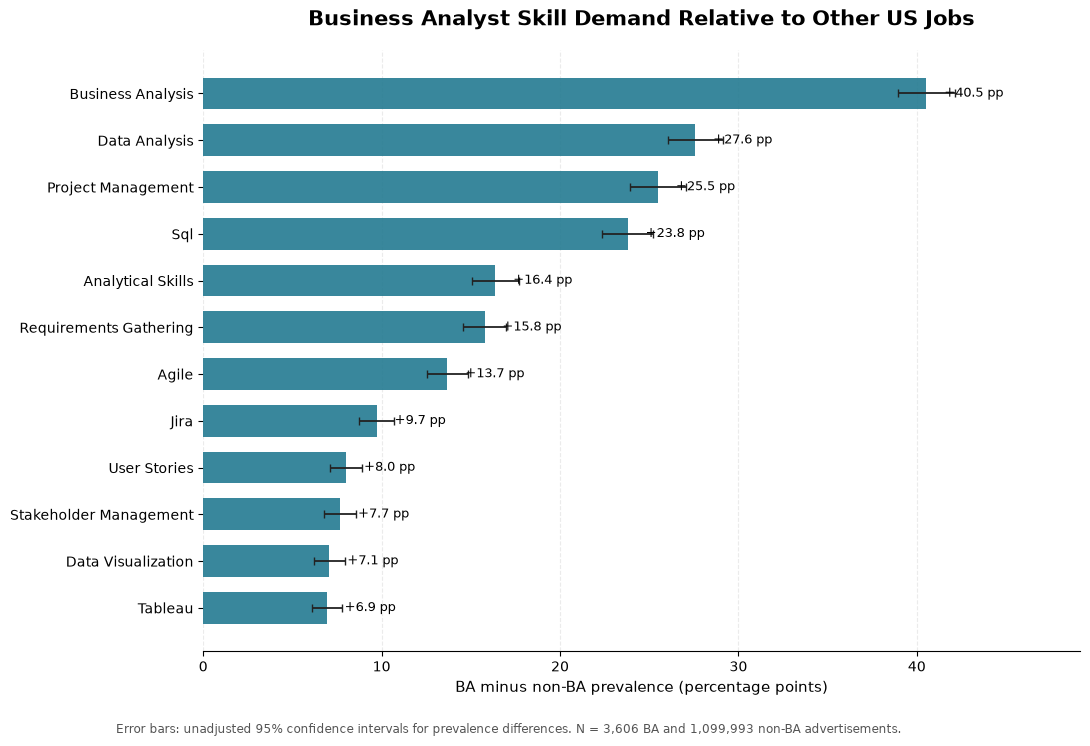

Figure 13 saved to: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ4_Figure_13_BA_Skill_Advantage.png


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# RQ4 - STEP 7.3A
# FIGURE 13: BA SKILL PREVALENCE ADVANTAGE
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

results = pd.read_csv(
    OUTPUT_DIR / "RQ4_SKILL_STATISTICAL_COMPARISON.csv"
)

# Selected substantive competencies
selected_skills = [
    "business analysis",
    "data analysis",
    "project management",
    "sql",
    "analytical skills",
    "requirements gathering",
    "agile",
    "jira",
    "user stories",
    "stakeholder management",
    "data visualization",
    "tableau"
]

figure_data = results[
    results["skill_standard"].isin(selected_skills)
].copy()

assert len(figure_data) == len(selected_skills), (
    "One or more selected skills are missing."
)

figure_data = figure_data.sort_values(
    "Difference_pp",
    ascending=True
)

# Error-bar lengths
lower_error = (
    figure_data["Difference_pp"]
    - figure_data["Difference_Lower_95_pp"]
)

upper_error = (
    figure_data["Difference_Upper_95_pp"]
    - figure_data["Difference_pp"]
)

# Create plot
fig, ax = plt.subplots(figsize=(11, 7.5))

bars = ax.barh(
    figure_data["skill_standard"].str.title(),
    figure_data["Difference_pp"],
    color="#237A91",
    alpha=0.9,
    height=0.68
)

ax.errorbar(
    figure_data["Difference_pp"],
    range(len(figure_data)),
    xerr=[lower_error, upper_error],
    fmt="none",
    ecolor="#222222",
    capsize=3,
    linewidth=1.3
)

# Labels
for bar, value in zip(
    bars,
    figure_data["Difference_pp"]
):
    ax.text(
        value + 1.0,
        bar.get_y() + bar.get_height() / 2,
        f"+{value:.1f} pp",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Business Analyst Skill Demand Relative to Other US Jobs",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "BA minus non-BA prevalence (percentage points)",
    fontsize=11
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    figure_data["Difference_Upper_95_pp"].max() + 7
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.11,
    0.015,
    "Error bars: unadjusted 95% confidence intervals for prevalence differences. "
    "N = 3,606 BA and 1,099,993 non-BA advertisements.",
    fontsize=8.5,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

figure_path = OUTPUT_DIR / "RQ4_Figure_13_BA_Skill_Advantage.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 13 saved to:", figure_path)


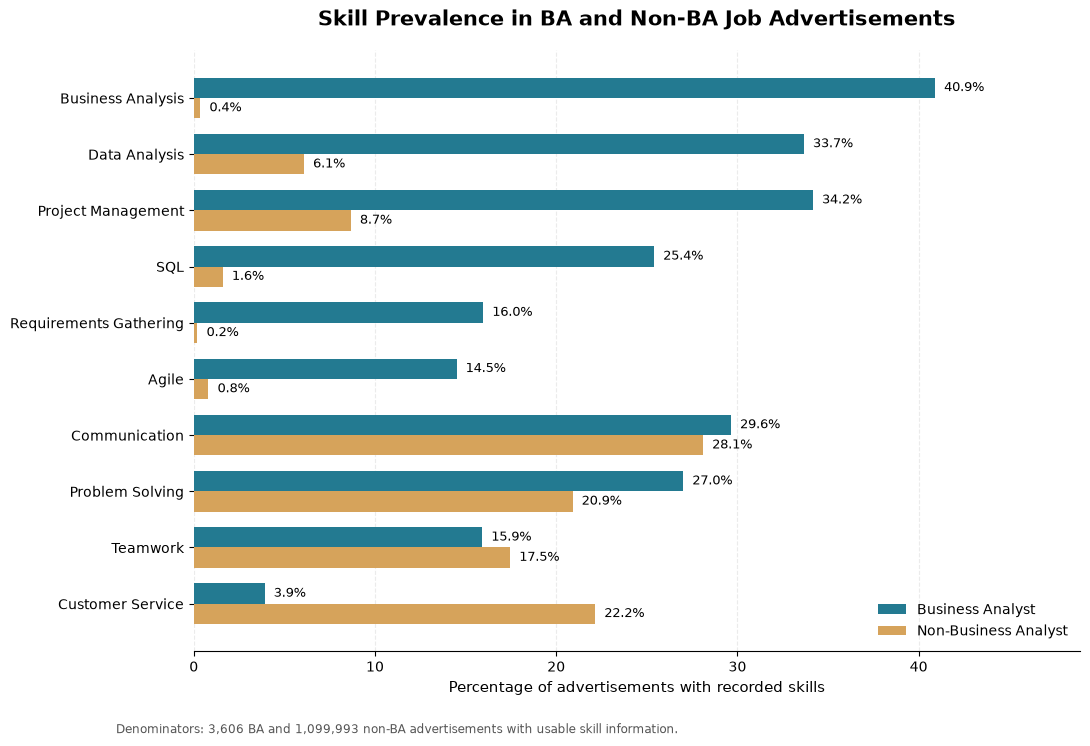

Figure 14 saved to: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ4_Figure_14_Skill_Prevalence_Comparison.png


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# RQ4 - STEP 7.3B
# FIGURE 14: BA VS NON-BA SKILL PREVALENCE
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

comparison = pd.read_csv(
    OUTPUT_DIR / "RQ4_ALL_SKILL_PREVALENCE_COMPARISON.csv"
)

selected_skills = [
    "business analysis",
    "data analysis",
    "project management",
    "sql",
    "requirements gathering",
    "agile",
    "communication",
    "problem solving",
    "teamwork",
    "customer service"
]

figure_data = comparison[
    comparison["skill_standard"].isin(selected_skills)
].copy()

assert len(figure_data) == len(selected_skills), (
    "One or more selected skills are missing."
)

# Preserve selected skill order
figure_data["skill_standard"] = pd.Categorical(
    figure_data["skill_standard"],
    categories=selected_skills,
    ordered=True
)

figure_data = figure_data.sort_values(
    "skill_standard"
).iloc[::-1]

labels = [
    "SQL" if skill == "sql" else skill.title()
    for skill in figure_data["skill_standard"].astype(str)
]

y = np.arange(len(figure_data))
bar_height = 0.36

fig, ax = plt.subplots(figsize=(11, 7.5))

ba_bars = ax.barh(
    y + bar_height / 2,
    figure_data["BA_Percentage"],
    height=bar_height,
    label="Business Analyst",
    color="#237A91"
)

non_ba_bars = ax.barh(
    y - bar_height / 2,
    figure_data["Non_BA_Percentage"],
    height=bar_height,
    label="Non-Business Analyst",
    color="#D6A35B"
)

# Percentage labels
for bars in [ba_bars, non_ba_bars]:
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va="center",
            fontsize=9
        )

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10)

ax.set_xlabel(
    "Percentage of advertisements with recorded skills",
    fontsize=11
)

ax.set_title(
    "Skill Prevalence in BA and Non-BA Job Advertisements",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.legend(
    loc="lower right",
    frameon=False
)

ax.set_xlim(
    0,
    max(
        figure_data["BA_Percentage"].max(),
        figure_data["Non_BA_Percentage"].max()
    ) + 8
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.11,
    0.015,
    "Denominators: 3,606 BA and 1,099,993 non-BA advertisements "
    "with usable skill information.",
    fontsize=8.5,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

figure_path = (
    OUTPUT_DIR / "RQ4_Figure_14_Skill_Prevalence_Comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 14 saved to:", figure_path)


In [9]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

# ============================================================
# RQ4 - STEP 7.4A
# BA SKILL ADVANTAGE ROBUSTNESS:
# EXCLUDE LARGEST BA ADVERTISER
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

# 1. Load BA job and skill data
ba_jobs = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv",
    usecols=["job_link", "company"],
    dtype={"job_link": "string"}
)

ba_skills = pd.read_csv(
    OUTPUT_DIR / "US_BA_SKILLS_STANDARDISED.csv",
    usecols=["job_link", "skill_standard"],
    dtype={"job_link": "string"}
)

comparison = pd.read_csv(
    OUTPUT_DIR / "RQ4_SKILL_STATISTICAL_COMPARISON.csv"
)

# 2. Identify largest advertiser
advertiser_counts = (
    ba_jobs["company"]
    .fillna("Unknown")
    .value_counts()
)

largest_advertiser = advertiser_counts.index[0]

largest_links = set(
    ba_jobs.loc[
        ba_jobs["company"] == largest_advertiser,
        "job_link"
    ]
)

# 3. Exclude its advertisements from BA skills
ba_skills = ba_skills.drop_duplicates(
    subset=["job_link", "skill_standard"]
)

ba_skills_filtered = ba_skills[
    ~ba_skills["job_link"].isin(largest_links)
].copy()

N_BA_ORIGINAL = ba_skills["job_link"].nunique()
N_BA_FILTERED = ba_skills_filtered["job_link"].nunique()

# 4. Recalculate skill prevalence
filtered_counts = (
    ba_skills_filtered
    .groupby("skill_standard")["job_link"]
    .nunique()
    .rename("BA_Postings_Filtered")
    .reset_index()
)

robustness = comparison.merge(
    filtered_counts,
    on="skill_standard",
    how="left"
)

robustness["BA_Postings_Filtered"] = (
    robustness["BA_Postings_Filtered"]
    .fillna(0)
    .astype(int)
)

robustness["BA_Percentage_Filtered"] = (
    robustness["BA_Postings_Filtered"]
    / N_BA_FILTERED * 100
)

robustness["Difference_pp_Filtered"] = (
    robustness["BA_Percentage_Filtered"]
    - robustness["Non_BA_Percentage"]
)

robustness["Difference_Change_pp"] = (
    robustness["Difference_pp_Filtered"]
    - robustness["Difference_pp"]
)

robustness["Advantage_Retained"] = (
    robustness["Difference_pp_Filtered"] > 0
)

# 5. Selected competencies from Figure 13
selected_skills = [
    "business analysis",
    "data analysis",
    "project management",
    "sql",
    "analytical skills",
    "requirements gathering",
    "agile",
    "jira",
    "user stories",
    "stakeholder management",
    "data visualization",
    "tableau"
]

selected_robustness = robustness[
    robustness["skill_standard"].isin(selected_skills)
].copy()

selected_robustness = selected_robustness.sort_values(
    "Difference_pp",
    ascending=False
)

# 6. Results
print("=" * 65)
print("RQ4 - ADVERTISER ROBUSTNESS")
print("=" * 65)

print("Largest advertiser:", largest_advertiser)
print("Advertisements from largest advertiser:",
      len(largest_links))

print("\nOriginal BA advertisements with skills:",
      N_BA_ORIGINAL)

print("Remaining BA advertisements with skills:",
      N_BA_FILTERED)

print("\nSelected skill advantages retained:",
      selected_robustness["Advantage_Retained"].sum(),
      "out of",
      len(selected_robustness))

print("\nSELECTED COMPETENCY COMPARISON:")

display(
    selected_robustness[
        [
            "skill_standard",
            "Difference_pp",
            "Difference_pp_Filtered",
            "Difference_Change_pp",
            "Advantage_Retained"
        ]
    ].round(3)
)

# 7. Save results
robustness.to_csv(
    OUTPUT_DIR / "RQ4_ADVERTISER_ROBUSTNESS.csv",
    index=False
)

print("\nRobustness results saved successfully.")


RQ4 - ADVERTISER ROBUSTNESS
Largest advertiser: LATICRETE International
Advertisements from largest advertiser: 312

Original BA advertisements with skills: 3606
Remaining BA advertisements with skills: 3310

Selected skill advantages retained: 12 out of 12

SELECTED COMPETENCY COMPARISON:


,skill_standard,Difference_pp,Difference_pp_Filtered,Difference_Change_pp,Advantage_Retained
30,business analysis,40.542,43.807,3.265,True
80,data analysis,27.584,24.009,-3.575,True
283,project management,25.499,27.104,1.605,True
339,sql,23.798,21.024,-2.774,True
13,analytical skills,16.375,12.012,-4.364,True
305,requirements gathering,15.769,16.956,1.187,True
7,agile,13.692,11.545,-2.147,True
200,jira,9.727,10.612,0.885,True
402,user stories,8.016,8.738,0.722,True
345,stakeholder management,7.678,8.370,0.691,True



Robustness results saved successfully.


In [10]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

# ============================================================
# RQ4 - STEP 7.4B
# TOP-FIVE ADVERTISER ROBUSTNESS
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

# 1. Load data
ba_jobs = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv",
    usecols=["job_link", "company"],
    dtype={"job_link": "string"}
)

ba_skills = pd.read_csv(
    OUTPUT_DIR / "US_BA_SKILLS_STANDARDISED.csv",
    usecols=["job_link", "skill_standard"],
    dtype={"job_link": "string"}
)

comparison = pd.read_csv(
    OUTPUT_DIR / "RQ4_SKILL_STATISTICAL_COMPARISON.csv"
)

ba_skills = ba_skills.drop_duplicates(
    subset=["job_link", "skill_standard"]
)

# 2. Identify top five advertisers
top_five = (
    ba_jobs["company"]
    .fillna("Unknown")
    .value_counts()
    .head(5)
    .index
    .tolist()
)

print("TOP FIVE BA ADVERTISERS:")
for i, advertiser in enumerate(top_five, 1):
    print(f"{i}. {advertiser}")

# 3. Create exclusion sets
largest_links = set(
    ba_jobs.loc[
        ba_jobs["company"] == top_five[0],
        "job_link"
    ]
)

top5_links = set(
    ba_jobs.loc[
        ba_jobs["company"].isin(top_five),
        "job_link"
    ]
)

# 4. Create three skill datasets
scenarios = {
    "Original": ba_skills,
    "Exclude_Largest": ba_skills[
        ~ba_skills["job_link"].isin(largest_links)
    ],
    "Exclude_Top5": ba_skills[
        ~ba_skills["job_link"].isin(top5_links)
    ]
}

# 5. Calculate prevalence in each scenario
robustness = comparison[
    [
        "skill_standard",
        "Non_BA_Percentage",
        "Difference_pp"
    ]
].copy()

scenario_sizes = {}

for scenario_name, dataset in scenarios.items():

    n_jobs = dataset["job_link"].nunique()
    scenario_sizes[scenario_name] = n_jobs

    counts = (
        dataset.groupby("skill_standard")["job_link"]
        .nunique()
    )

    prevalence = (
        counts / n_jobs * 100
    )

    robustness[
        f"{scenario_name}_BA_Percentage"
    ] = (
        robustness["skill_standard"]
        .map(prevalence)
        .fillna(0)
    )

    robustness[
        f"{scenario_name}_Difference_pp"
    ] = (
        robustness[
            f"{scenario_name}_BA_Percentage"
        ]
        - robustness["Non_BA_Percentage"]
    )

# 6. Select competencies from Figure 13
selected_skills = [
    "business analysis",
    "data analysis",
    "project management",
    "sql",
    "analytical skills",
    "requirements gathering",
    "agile",
    "jira",
    "user stories",
    "stakeholder management",
    "data visualization",
    "tableau"
]

selected = robustness[
    robustness["skill_standard"].isin(selected_skills)
].copy()

selected["Retained_All_Scenarios"] = (
    (selected["Original_Difference_pp"] > 0)
    & (selected["Exclude_Largest_Difference_pp"] > 0)
    & (selected["Exclude_Top5_Difference_pp"] > 0)
)

selected = selected.sort_values(
    "Original_Difference_pp",
    ascending=False
)

# 7. Display results
print("\n" + "=" * 65)
print("RQ4 - TOP-FIVE ADVERTISER ROBUSTNESS")
print("=" * 65)

print("\nSKILLS-COVERED ADVERTISEMENTS:")
for name, size in scenario_sizes.items():
    print(f"{name}: {size:,}")

print("\nSELECTED COMPETENCIES:")

display(
    selected[
        [
            "skill_standard",
            "Original_Difference_pp",
            "Exclude_Largest_Difference_pp",
            "Exclude_Top5_Difference_pp",
            "Retained_All_Scenarios"
        ]
    ].round(3)
)

print("\nAdvantages retained across all scenarios:",
      selected["Retained_All_Scenarios"].sum(),
      "out of",
      len(selected))

# 8. Save results
robustness.to_csv(
    OUTPUT_DIR / "RQ4_TOP5_ADVERTISER_ROBUSTNESS.csv",
    index=False
)

print("\nTop-five advertiser robustness saved successfully.")


TOP FIVE BA ADVERTISERS:
1. LATICRETE International
2. Dice
3. Tata Consultancy Services
4. Stellent IT
5. NR Consulting

RQ4 - TOP-FIVE ADVERTISER ROBUSTNESS

SKILLS-COVERED ADVERTISEMENTS:
Original: 3,606
Exclude_Largest: 3,310
Exclude_Top5: 2,977

SELECTED COMPETENCIES:


,skill_standard,Original_Difference_pp,Exclude_Largest_Difference_pp,Exclude_Top5_Difference_pp,Retained_All_Scenarios
30,business analysis,40.542,43.807,43.742,True
80,data analysis,27.584,24.009,24.687,True
283,project management,25.499,27.104,27.679,True
339,sql,23.798,21.024,21.171,True
13,analytical skills,16.375,12.012,12.809,True
305,requirements gathering,15.769,16.956,16.625,True
7,agile,13.692,11.545,11.415,True
200,jira,9.727,10.612,10.310,True
402,user stories,8.016,8.738,8.579,True
345,stakeholder management,7.678,8.370,8.443,True



Advantages retained across all scenarios: 12 out of 12

Top-five advertiser robustness saved successfully.


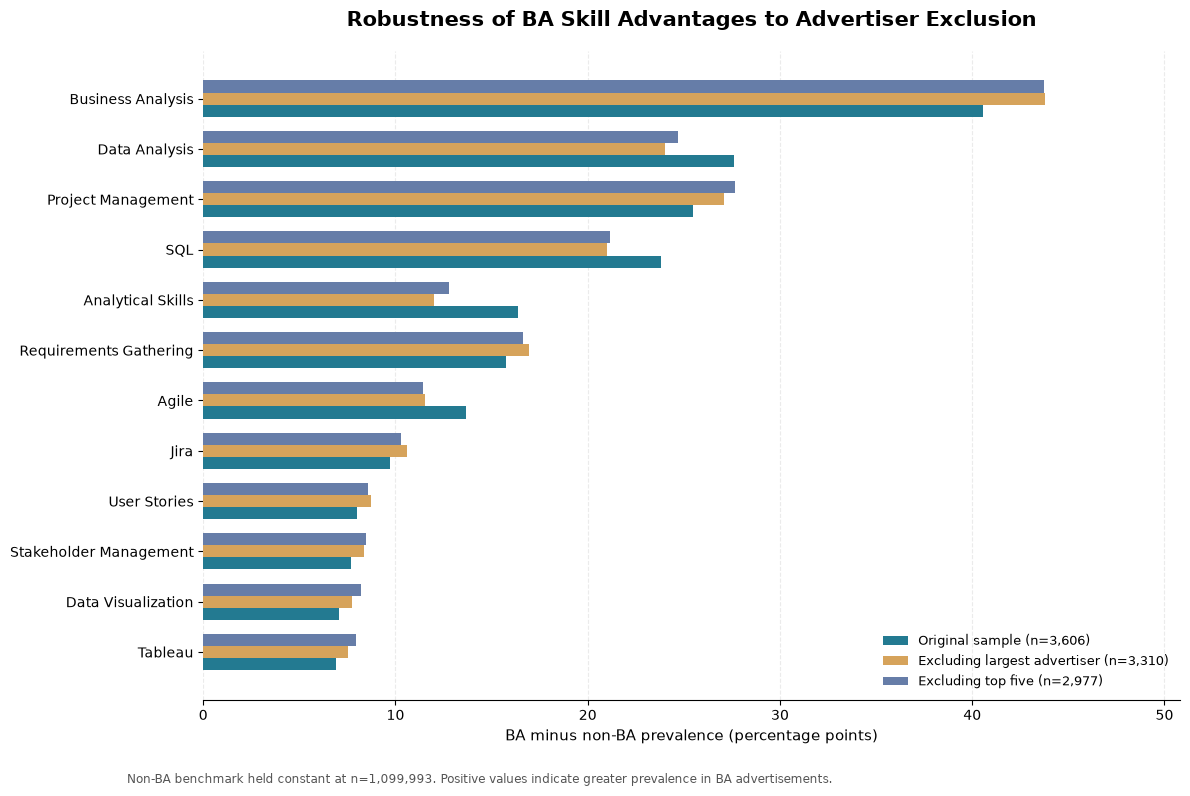

Figure 15 saved to: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ4_Figure_15_Advertiser_Robustness.png


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# RQ4 - STEP 7.4C
# FIGURE 15: ADVERTISER ROBUSTNESS
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

robustness = pd.read_csv(
    OUTPUT_DIR / "RQ4_TOP5_ADVERTISER_ROBUSTNESS.csv"
)

selected_skills = [
    "business analysis",
    "data analysis",
    "project management",
    "sql",
    "analytical skills",
    "requirements gathering",
    "agile",
    "jira",
    "user stories",
    "stakeholder management",
    "data visualization",
    "tableau"
]

figure_data = robustness[
    robustness["skill_standard"].isin(selected_skills)
].copy()

assert len(figure_data) == len(selected_skills), (
    "One or more selected skills are missing."
)

figure_data = figure_data.sort_values(
    "Original_Difference_pp",
    ascending=True
)

labels = [
    "SQL" if skill == "sql" else skill.title()
    for skill in figure_data["skill_standard"]
]

y = np.arange(len(figure_data))
bar_height = 0.24

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    y - bar_height,
    figure_data["Original_Difference_pp"],
    height=bar_height,
    label="Original sample (n=3,606)",
    color="#237A91"
)

ax.barh(
    y,
    figure_data["Exclude_Largest_Difference_pp"],
    height=bar_height,
    label="Excluding largest advertiser (n=3,310)",
    color="#D6A35B"
)

ax.barh(
    y + bar_height,
    figure_data["Exclude_Top5_Difference_pp"],
    height=bar_height,
    label="Excluding top five (n=2,977)",
    color="#667DA8"
)

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10)

ax.set_xlabel(
    "BA minus non-BA prevalence (percentage points)",
    fontsize=11
)

ax.set_title(
    "Robustness of BA Skill Advantages to Advertiser Exclusion",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=9
)

ax.set_xlim(
    0,
    figure_data[
        [
            "Original_Difference_pp",
            "Exclude_Largest_Difference_pp",
            "Exclude_Top5_Difference_pp"
        ]
    ].to_numpy().max() + 7
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

fig.text(
    0.11,
    0.015,
    "Non-BA benchmark held constant at n=1,099,993. "
    "Positive values indicate greater prevalence in BA advertisements.",
    fontsize=8.5,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

figure_path = (
    OUTPUT_DIR / "RQ4_Figure_15_Advertiser_Robustness.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 15 saved to:", figure_path)


In [12]:

import pandas as pd
import numpy as np
import re
from pathlib import Path
from IPython.display import display

# ============================================================
# RQ - FINAL ROBUSTNESS: POTENTIAL REPOST / DUPLICATE ANALYSIS
# ============================================================

DATA_DIR = Path(r"E:\Analytic Plan BI\LinkedIn Dataset")
OUTPUT_DIR = DATA_DIR / "Assignment_2_Analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load frozen BA cohort
ba = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv",
    dtype={"job_link": "string"}
)

print("=" * 65)
print("FINAL ROBUSTNESS - DUPLICATE ADVERTISEMENT SCREENING")
print("=" * 65)

print("\nTotal BA advertisements:", len(ba))
print("\nAvailable columns:")
print(ba.columns.tolist())

# ------------------------------------------------------------
# 1. Identify available title and location fields
# ------------------------------------------------------------

title_candidates = [
    "job_title", "title", "job_title_clean",
    "title_clean", "position"
]

location_candidates = [
    "job_location", "location", "location_clean"
]

title_col = next(
    (c for c in title_candidates if c in ba.columns),
    None
)

location_col = next(
    (c for c in location_candidates if c in ba.columns),
    None
)

company_col = "company" if "company" in ba.columns else None

if title_col is None:
    raise ValueError(
        "No job-title column found. Review the printed columns."
    )

if location_col is None or company_col is None:
    raise ValueError(
        "Company or location column missing. Review the columns."
    )

print("\nFields selected:")
print("Title:", title_col)
print("Company:", company_col)
print("Location:", location_col)

# ------------------------------------------------------------
# 2. Conservative text normalisation
# ------------------------------------------------------------

def normalise_text(value):
    if pd.isna(value):
        return ""

    value = str(value).lower().strip()
    value = re.sub(r"[^a-z0-9]+", " ", value)
    value = re.sub(r"\s+", " ", value)

    return value.strip()

ba["title_norm"] = ba[title_col].map(normalise_text)
ba["company_norm"] = ba[company_col].map(normalise_text)
ba["location_norm"] = ba[location_col].map(normalise_text)

# Do not group blank or unknown identifiers together
valid_company = ba["company_norm"].ne("")
valid_title = ba["title_norm"].ne("")
valid_location = ba["location_norm"].ne("")

# ------------------------------------------------------------
# 3. Level 1: Exact job_link duplication
# ------------------------------------------------------------

exact_duplicate_rows = ba["job_link"].duplicated(
    keep=False
).sum()

print("\nLEVEL 1 - EXACT URL DUPLICATION")
print("Rows sharing a job_link:", exact_duplicate_rows)

# ------------------------------------------------------------
# 4. Level 2: Company + title + location
# ------------------------------------------------------------

strict_cols = [
    "company_norm",
    "title_norm",
    "location_norm"
]

strict_valid = valid_company & valid_title & valid_location

strict_groups = (
    ba.loc[strict_valid]
    .groupby(strict_cols, dropna=False)
    .agg(
        Advertisements=("job_link", "size"),
        Unique_Links=("job_link", "nunique")
    )
    .reset_index()
    .sort_values("Advertisements", ascending=False)
)

strict_candidates = strict_groups[
    strict_groups["Advertisements"] > 1
].copy()

strict_candidate_ads = int(
    strict_candidates["Advertisements"].sum()
)

strict_excess_ads = int(
    (strict_candidates["Advertisements"] - 1).sum()
)

print("\nLEVEL 2 - COMPANY + TITLE + LOCATION")
print("Repeated groups:", len(strict_candidates))
print("Advertisements in repeated groups:", strict_candidate_ads)
print("Potential excess advertisements:", strict_excess_ads)
print(
    "Potential excess share:",
    round(strict_excess_ads / len(ba) * 100, 2),
    "%"
)

print("\nTOP 20 STRICT-MATCH GROUPS:")
display(strict_candidates.head(20))

# ------------------------------------------------------------
# 5. Level 3: Company + title, ignoring location
# ------------------------------------------------------------

broad_cols = ["company_norm", "title_norm"]
broad_valid = valid_company & valid_title

broad_groups = (
    ba.loc[broad_valid]
    .groupby(broad_cols, dropna=False)
    .agg(
        Advertisements=("job_link", "size"),
        Distinct_Locations=("location_norm", "nunique")
    )
    .reset_index()
    .sort_values("Advertisements", ascending=False)
)

broad_candidates = broad_groups[
    broad_groups["Advertisements"] > 1
].copy()

print("\nLEVEL 3 - COMPANY + TITLE")
print("Repeated groups:", len(broad_candidates))
print(
    "Advertisements in repeated groups:",
    int(broad_candidates["Advertisements"].sum())
)

print("\nTOP 20 BROAD-MATCH GROUPS:")
display(broad_candidates.head(20))

# ------------------------------------------------------------
# 6. Flag potential reposts in original cohort
# ------------------------------------------------------------

ba["potential_repost"] = False

ba.loc[strict_valid, "potential_repost"] = (
    ba.loc[strict_valid]
    .duplicated(subset=strict_cols, keep=False)
)

# ------------------------------------------------------------
# 7. Advertisers contributing most candidate reposts
# ------------------------------------------------------------

repost_by_company = (
    ba.loc[ba["potential_repost"]]
    .groupby("company", dropna=False)
    .agg(
        Candidate_Advertisements=("job_link", "size"),
        Candidate_Groups=(
            "title_norm",
            "nunique"
        )
    )
    .reset_index()
    .sort_values(
        "Candidate_Advertisements",
        ascending=False
    )
)

print("\nTOP ADVERTISERS IN STRICT-MATCH CANDIDATES:")
display(repost_by_company.head(20))

# ------------------------------------------------------------
# 8. Save outputs
# ------------------------------------------------------------

strict_candidates.to_csv(
    OUTPUT_DIR / "FINAL_STRICT_REPOST_CANDIDATES.csv",
    index=False
)

broad_candidates.to_csv(
    OUTPUT_DIR / "FINAL_BROAD_DUPLICATE_CANDIDATES.csv",
    index=False
)

repost_by_company.to_csv(
    OUTPUT_DIR / "FINAL_REPOSTS_BY_ADVERTISER.csv",
    index=False
)

ba.to_csv(
    OUTPUT_DIR / "FINAL_BA_REPOST_FLAGS.csv",
    index=False
)

print("\nAll duplicate-screening outputs saved successfully.")


FINAL ROBUSTNESS - DUPLICATE ADVERTISEMENT SCREENING

Total BA advertisements: 3722

Available columns:
['job_link', 'job_title', 'company', 'job_location', 'first_seen', 'search_city', 'search_country', 'search_position', 'job_level', 'job_type', 'state_clean', 'location_country_issue']

Fields selected:
Title: job_title
Company: company
Location: job_location

LEVEL 1 - EXACT URL DUPLICATION
Rows sharing a job_link: 0

LEVEL 2 - COMPANY + TITLE + LOCATION
Repeated groups: 231
Advertisements in repeated groups: 585
Potential excess advertisements: 354
Potential excess share: 9.51 %

TOP 20 STRICT-MATCH GROUPS:


,company_norm,title_norm,location_norm,Advertisements,Unique_Links
1662,laticrete international,jd edwards business analyst,california united states,11,11
1892,laticrete international,jde business analyst supply chain,texas united states,9,9
2928,tata consultancy services,business analyst,boston ma,9,9
1783,laticrete international,jde business analyst supply chain,california united states,8,8
1323,hexaware technologies,erp fin business analyst,perrysburg oh,8,8
1762,laticrete international,jd edwards business analyst,texas united states,8,8
1322,hexaware technologies,erp fin business analyst,birmingham al,7,7
2168,nr consulting,business analyst,boulder co,7,7
2340,prime healthcare,business analyst i,ontario ca,7,7
1553,jobs for humanity,business analyst ii,maryland united states,6,6



LEVEL 3 - COMPANY + TITLE
Repeated groups: 307
Advertisements in repeated groups: 1384

TOP 20 BROAD-MATCH GROUPS:


,company_norm,title_norm,Advertisements,Distinct_Locations
1408,laticrete international,jde business analyst supply chain,163,131
1407,laticrete international,jd edwards business analyst,149,119
2282,tata consultancy services,business analyst,54,24
595,dice,business analyst,39,31
2149,stellent it,business analyst,27,21
1656,nr consulting,business analyst,25,12
917,ey,senior financial business analyst tax technology,22,22
1934,robert half,business analyst,19,18
1850,pwc,guidewire business analyst senior associate,18,18
2043,software technology inc,business analyst,17,8



TOP ADVERTISERS IN STRICT-MATCH CANDIDATES:


,company,Candidate_Advertisements,Candidate_Groups
55,LATICRETE International,92,2
99,Tata Consultancy Services,44,2
52,Jobs for Humanity,30,5
28,Dice,25,6
62,NR Consulting,23,3
86,Software Technology Inc.,17,2
44,Hexaware Technologies,15,1
56,Lennar,11,4
91,Stellent IT,10,1
50,Intellectt Inc,10,4



All duplicate-screening outputs saved successfully.


In [13]:

import pandas as pd
import numpy as np
import re
from pathlib import Path
from IPython.display import display

# ============================================================
# FINAL ROBUSTNESS - STRICT-MATCH DEDUPLICATION SENSITIVITY
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

# ------------------------------------------------------------
# 1. Load flagged BA cohort
# ------------------------------------------------------------

ba = pd.read_csv(
    OUTPUT_DIR / "FINAL_BA_REPOST_FLAGS.csv",
    dtype={"job_link": "string"}
)

ba_skills = pd.read_csv(
    OUTPUT_DIR / "US_BA_SKILLS_STANDARDISED.csv",
    usecols=["job_link", "skill_standard"],
    dtype={"job_link": "string"}
)

ba_skills = ba_skills.drop_duplicates(
    subset=["job_link", "skill_standard"]
)

# ------------------------------------------------------------
# 2. Construct strict-match sensitivity cohort
# ------------------------------------------------------------

strict_cols = [
    "company_norm",
    "title_norm",
    "location_norm"
]

# Avoid merging advertisements with missing identifiers
valid = (
    ba[strict_cols]
    .fillna("")
    .ne("")
    .all(axis=1)
)

# Deterministic selection: earliest observed advertisement
ba["first_seen_sort"] = pd.to_datetime(
    ba["first_seen"],
    errors="coerce",
    utc=True
)

ba_sorted = ba.sort_values(
    ["first_seen_sort", "job_link"],
    na_position="last"
)

valid_rows = ba_sorted.loc[valid.reindex(ba_sorted.index)]

dedup_valid = valid_rows.drop_duplicates(
    subset=strict_cols,
    keep="first"
)

invalid_rows = ba_sorted.loc[
    ~valid.reindex(ba_sorted.index)
]

ba_dedup = pd.concat(
    [dedup_valid, invalid_rows],
    ignore_index=True
)

# ------------------------------------------------------------
# 3. Validate cohort sizes
# ------------------------------------------------------------

original_n = len(ba)
dedup_n = len(ba_dedup)
removed_n = original_n - dedup_n

print("=" * 65)
print("STRICT-MATCH DEDUPLICATION SENSITIVITY")
print("=" * 65)

print("Original BA advertisements:", original_n)
print("Sensitivity BA advertisements:", dedup_n)
print("Advertisements removed:", removed_n)
print("Removed percentage:", round(
    removed_n / original_n * 100, 2
))

print("Duplicate job links remaining:",
      ba_dedup["job_link"].duplicated().sum())

assert original_n == 3722
assert removed_n == 354, (
    "Unexpected deduplication count. "
    "Check the strict-match fields."
)

# ------------------------------------------------------------
# 4. Compare geographic distribution
# ------------------------------------------------------------

def state_counts(df):
    return (
        df.loc[df["state_clean"].notna()]
        .groupby("state_clean")["job_link"]
        .nunique()
    )

geo_original = state_counts(ba)
geo_dedup = state_counts(ba_dedup)

geo_compare = pd.DataFrame({
    "Original": geo_original,
    "Deduplicated": geo_dedup
}).fillna(0).astype(int)

geo_compare["Change"] = (
    geo_compare["Deduplicated"]
    - geo_compare["Original"]
)

geo_compare["Change_Pct"] = np.where(
    geo_compare["Original"] > 0,
    geo_compare["Change"]
    / geo_compare["Original"] * 100,
    np.nan
)

print("\nTOP 15 STATES BY ORIGINAL ADVERTISEMENTS:")
display(
    geo_compare.sort_values(
        "Original",
        ascending=False
    ).head(15).round(2)
)

# ------------------------------------------------------------
# 5. Compare advertiser concentration
# ------------------------------------------------------------

def advertiser_metrics(df):
    counts = (
        df["company"]
        .fillna("Unknown")
        .value_counts()
    )

    shares = counts / len(df)

    return {
        "Advertisements": len(df),
        "Advertisers": len(counts),
        "CR1_Pct": shares.iloc[:1].sum() * 100,
        "CR5_Pct": shares.iloc[:5].sum() * 100,
        "CR10_Pct": shares.iloc[:10].sum() * 100,
        "HHI": (shares ** 2).sum() * 10000
    }

advertiser_comparison = pd.DataFrame(
    {
        "Original": advertiser_metrics(ba),
        "Deduplicated": advertiser_metrics(ba_dedup)
    }
).T

print("\nADVERTISER CONCENTRATION COMPARISON:")
display(advertiser_comparison.round(3))

# ------------------------------------------------------------
# 6. Compare selected skill prevalence
# ------------------------------------------------------------

selected_skills = [
    "business analysis",
    "data analysis",
    "project management",
    "sql",
    "analytical skills",
    "requirements gathering",
    "agile",
    "jira",
    "user stories",
    "stakeholder management",
    "data visualization",
    "tableau"
]

original_skill_links = set(
    ba_skills["job_link"].dropna()
)

dedup_links = set(
    ba_dedup["job_link"].dropna()
)

dedup_skill_links = dedup_links & original_skill_links

N_ORIGINAL_SKILLS = len(original_skill_links)
N_DEDUP_SKILLS = len(dedup_skill_links)

original_skill_counts = (
    ba_skills.groupby("skill_standard")["job_link"]
    .nunique()
)

dedup_skill_counts = (
    ba_skills[
        ba_skills["job_link"].isin(dedup_skill_links)
    ]
    .groupby("skill_standard")["job_link"]
    .nunique()
)

skill_comparison = pd.DataFrame({
    "skill_standard": selected_skills
})

skill_comparison["Original_Pct"] = (
    skill_comparison["skill_standard"]
    .map(original_skill_counts)
    .fillna(0)
    / N_ORIGINAL_SKILLS * 100
)

skill_comparison["Deduplicated_Pct"] = (
    skill_comparison["skill_standard"]
    .map(dedup_skill_counts)
    .fillna(0)
    / N_DEDUP_SKILLS * 100
)

skill_comparison["Change_pp"] = (
    skill_comparison["Deduplicated_Pct"]
    - skill_comparison["Original_Pct"]
)

print("\nSKILLS-COVERED ADVERTISEMENTS:")
print("Original:", N_ORIGINAL_SKILLS)
print("Deduplicated:", N_DEDUP_SKILLS)

print("\nSELECTED SKILL PREVALENCE COMPARISON:")
display(skill_comparison.round(3))

# ------------------------------------------------------------
# 7. Save sensitivity outputs
# ------------------------------------------------------------

ba_dedup.to_csv(
    OUTPUT_DIR / "FINAL_BA_STRICT_DEDUP_COHORT.csv",
    index=False
)

geo_compare.to_csv(
    OUTPUT_DIR / "FINAL_DEDUP_GEOGRAPHIC_COMPARISON.csv"
)

advertiser_comparison.to_csv(
    OUTPUT_DIR / "FINAL_DEDUP_ADVERTISER_COMPARISON.csv"
)

skill_comparison.to_csv(
    OUTPUT_DIR / "FINAL_DEDUP_SKILL_COMPARISON.csv",
    index=False
)

print("\nDeduplication sensitivity outputs saved successfully.")


STRICT-MATCH DEDUPLICATION SENSITIVITY
Original BA advertisements: 3722
Sensitivity BA advertisements: 3368
Advertisements removed: 354
Removed percentage: 9.51
Duplicate job links remaining: 0

TOP 15 STATES BY ORIGINAL ADVERTISEMENTS:


,Original,Deduplicated,Change,Change_Pct
state_clean,,,,
TX,341,299,-42,-12.32
CA,339,299,-40,-11.80
FL,279,266,-13,-4.66
NY,255,235,-20,-7.84
NJ,205,192,-13,-6.34
VA,180,158,-22,-12.22
MA,165,137,-28,-16.97
NC,158,146,-12,-7.59
GA,157,138,-19,-12.10



ADVERTISER CONCENTRATION COMPARISON:


,Advertisements,Advertisers,CR1_Pct,CR5_Pct,CR10_Pct,HHI
Original,3722.0,1356.0,8.383,17.786,22.730,116.352
Deduplicated,3368.0,1356.0,7.423,15.825,20.249,97.709



SKILLS-COVERED ADVERTISEMENTS:
Original: 3606
Deduplicated: 3284

SELECTED SKILL PREVALENCE COMPARISON:


,skill_standard,Original_Pct,Deduplicated_Pct,Change_pp
0,business analysis,40.904,41.565,0.661
1,data analysis,33.666,33.130,-0.536
2,project management,34.165,34.714,0.548
3,sql,25.402,25.152,-0.250
4,analytical skills,20.799,20.646,-0.153
5,requirements gathering,15.973,16.139,0.165
6,agile,14.504,14.342,-0.161
7,jira,10.233,10.079,-0.154
8,user stories,8.070,8.009,-0.061
9,stakeholder management,8.070,8.313,0.243



Deduplication sensitivity outputs saved successfully.
